In [1]:
import pickle
import networkx as nx
import pandas as pd

with open("../data/processed/research_graph.pkl", "rb") as f:
    G = pickle.load(f)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 767
Edges: 11064


In [2]:
import community as community_louvain

partition = community_louvain.best_partition(
    G,
    weight="weight",
    random_state=42
)

print("Number of communities:", len(set(partition.values())))

Number of communities: 124


In [3]:
nx.set_node_attributes(
    G,
    partition,
    "community"
)

print("Community assignments added.")

Community assignments added.


In [4]:
community_sizes = (
    pd.Series(partition)
    .value_counts()
    .sort_values(ascending=False)
)

print(community_sizes)

51    156
8     124
6      99
9      98
7      77
     ... 
60      1
59      1
58      1
57      1
71      1
Name: count, Length: 124, dtype: int64


In [5]:
print("Largest community:", community_sizes.iloc[0])
print("Smallest community:", community_sizes.iloc[-1])

Largest community: 156
Smallest community: 1


In [6]:
community_df = pd.DataFrame({
    "node": list(partition.keys()),
    "community": list(partition.values())
})

community_df["title"] = community_df["node"].map(
    nx.get_node_attributes(G, "title")
)

community_df["year"] = community_df["node"].map(
    nx.get_node_attributes(G, "year")
)

community_df["citation_count"] = community_df["node"].map(
    nx.get_node_attributes(G, "citation_count")
)

community_df.head()

,node,community,title,year,citation_count
0,0,0,A Comprehensive Overview of Large Language Models,2023,368
1,1,17,A Comprehensive Survey of Hallucination Mitiga...,2024,122
2,2,51,A Comprehensive Survey of Retrieval-Augmented ...,2024,23
3,3,3,A Comprehensive Survey of Retrieval-Augmented ...,2025,28
4,4,7,A Comprehensive Survey on Multimodal RAG: All ...,2025,2


In [7]:
top_communities = (
    community_sizes
    .head(10)
    .rename_axis("community")
    .reset_index(name="paper_count")
)

top_communities

,community,paper_count
0,51,156
1,8,124
2,6,99
3,9,98
4,7,77
5,17,33
6,14,22
7,0,20
8,48,7
9,13,6


In [8]:
for community_id in top_communities["community"]:
    
    print("\n" + "=" * 80)
    print(
        f"COMMUNITY {community_id} "
        f"({community_sizes[community_id]} papers)"
    )
    print("=" * 80)

    subset = community_df[
        community_df["community"] == community_id
    ].sort_values(
        "citation_count",
        ascending=False
    )

    print(
        subset[
            ["title", "year", "citation_count"]
        ].head(10).to_string(index=False)
    )


COMMUNITY 51 (156 papers)
                                                                                                            title  year  citation_count
                                                        Lost in the Middle: How Language Models Use Long Contexts  2024            1333
                           Leveraging Passage Retrieval with Generative Models for Open Domain Question Answering  2021            1009
                                  A Survey on RAG Meeting LLMs: Towards Retrieval-Augmented Large Language Models  2024             757
                                               Retrieval-Augmented Generation for Large Language Models: A Survey  2023             748
                                                           REALM: Retrieval-Augmented Language Model Pre-Training  2020             513
                                                                   In-Context Retrieval-Augmented Language Models  2023             407
                     

In [9]:
community_stats = (
    community_df
    .groupby("community")
    .agg(
        paper_count=("node", "count"),
        avg_citations=("citation_count", "mean"),
        max_citations=("citation_count", "max"),
        avg_year=("year", "mean")
    )
    .sort_values(
        "paper_count",
        ascending=False
    )
)

community_stats.head(15)

,paper_count,avg_citations,max_citations,avg_year
community,,,,
51,156,68.250000,1333,2024.115385
8,124,117.072581,3909,2024.443548
6,99,25.636364,153,2024.707071
9,98,31.357143,286,2024.704082
7,77,13.064935,231,2024.740260
17,33,272.696970,3352,2023.969697
14,22,106.000000,1045,2024.545455
0,20,759.150000,3868,2023.300000
48,7,38.857143,178,2024.428571


In [10]:
community_df.to_parquet(
    "../data/processed/community_assignments.parquet",
    index=False
)

print("Community assignments saved successfully.")

Community assignments saved successfully.


In [11]:
with open(
    "../data/processed/research_graph_communities.pkl",
    "wb"
) as f:
    pickle.dump(G, f)

print("Graph with communities saved successfully.")

Graph with communities saved successfully.


In [12]:
# Build a compact summary for each community

community_summary = (
    community_df
    .groupby("community")
    .agg(
        paper_count=("node", "count"),
        avg_citations=("citation_count", "mean"),
        max_citations=("citation_count", "max"),
        avg_year=("year", "mean")
    )
    .sort_values("paper_count", ascending=False)
)

community_summary.head(15)

,paper_count,avg_citations,max_citations,avg_year
community,,,,
51,156,68.250000,1333,2024.115385
8,124,117.072581,3909,2024.443548
6,99,25.636364,153,2024.707071
9,98,31.357143,286,2024.704082
7,77,13.064935,231,2024.740260
17,33,272.696970,3352,2023.969697
14,22,106.000000,1045,2024.545455
0,20,759.150000,3868,2023.300000
48,7,38.857143,178,2024.428571


In [13]:
# Show top 5 papers for each major community

for community_id in community_summary.head(10).index:

    subset = (
        community_df[
            community_df["community"] == community_id
        ]
        .sort_values("citation_count", ascending=False)
        .head(5)
    )

    print("\n" + "=" * 90)
    print(
        f"COMMUNITY {community_id} "
        f" | {len(community_df[community_df['community'] == community_id])} papers"
    )
    print("=" * 90)

    for _, row in subset.iterrows():
        print(
            f"- {row['title']} "
            f"({row['year']}, {row['citation_count']} citations)"
        )# Show top 5 papers for each major community

for community_id in community_summary.head(10).index:

    subset = (
        community_df[
            community_df["community"] == community_id
        ]
        .sort_values("citation_count", ascending=False)
        .head(5)
    )

    print("\n" + "=" * 90)
    print(
        f"COMMUNITY {community_id} "
        f" | {len(community_df[community_df['community'] == community_id])} papers"
    )
    print("=" * 90)

    for _, row in subset.iterrows():
        print(
            f"- {row['title']} "
            f"({row['year']}, {row['citation_count']} citations)"
        )


COMMUNITY 51  | 156 papers
- Lost in the Middle: How Language Models Use Long Contexts (2024, 1333 citations)
- Leveraging Passage Retrieval with Generative Models for Open Domain Question Answering (2021, 1009 citations)
- A Survey on RAG Meeting LLMs: Towards Retrieval-Augmented Large Language Models (2024, 757 citations)
- Retrieval-Augmented Generation for Large Language Models: A Survey (2023, 748 citations)
- REALM: Retrieval-Augmented Language Model Pre-Training (2020, 513 citations)

COMMUNITY 8  | 124 papers
- Large language models encode clinical knowledge (2023, 3909 citations)
- The future landscape of large language models in medicine (2023, 1054 citations)
- Toward expert-level medical question answering with large language models (2025, 959 citations)
- Attention is not all you need: the complicated case of ethically using large language models in healthcare and medicine (2023, 482 citations)
- Almanac — Retrieval-Augmented Language Models for Clinical Medicine (2024, 4

In [15]:
# Compact thematic analysis of the 10 largest communities

major_communities = community_summary.head(10).index

for community_id in major_communities:

    subset = (
        community_df[
            community_df["community"] == community_id
        ]
        .sort_values("citation_count", ascending=False)
    )

    print("\n" + "=" * 70)
    print(f"COMMUNITY {community_id} | {len(subset)} papers")
    print("=" * 70)

    print("\nTop papers:")

    for _, row in subset.head(5).iterrows():
        print(
            f"- {row['title']} "
            f"({int(row['year'])}, {int(row['citation_count'])} citations)"
        )


COMMUNITY 51 | 156 papers

Top papers:
- Lost in the Middle: How Language Models Use Long Contexts (2024, 1333 citations)
- Leveraging Passage Retrieval with Generative Models for Open Domain Question Answering (2021, 1009 citations)
- A Survey on RAG Meeting LLMs: Towards Retrieval-Augmented Large Language Models (2024, 757 citations)
- Retrieval-Augmented Generation for Large Language Models: A Survey (2023, 748 citations)
- REALM: Retrieval-Augmented Language Model Pre-Training (2020, 513 citations)

COMMUNITY 8 | 124 papers

Top papers:
- Large language models encode clinical knowledge (2023, 3909 citations)
- The future landscape of large language models in medicine (2023, 1054 citations)
- Toward expert-level medical question answering with large language models (2025, 959 citations)
- Attention is not all you need: the complicated case of ethically using large language models in healthcare and medicine (2023, 482 citations)
- Almanac — Retrieval-Augmented Language Models for Cl

In [16]:
# Compact overview of the 10 largest communities

top10 = community_summary.head(10).index

community_overview = []

for community_id in top10:

    subset = (
        community_df[
            community_df["community"] == community_id
        ]
        .sort_values("citation_count", ascending=False)
    )

    top_titles = subset.head(3)["title"].tolist()

    community_overview.append({
        "community": community_id,
        "paper_count": len(subset),
        "top_paper_1": top_titles[0] if len(top_titles) > 0 else "",
        "top_paper_2": top_titles[1] if len(top_titles) > 1 else "",
        "top_paper_3": top_titles[2] if len(top_titles) > 2 else ""
    })

community_overview_df = pd.DataFrame(community_overview)

community_overview_df

,community,paper_count,top_paper_1,top_paper_2,top_paper_3
0,51,156,Lost in the Middle: How Language Models Use Lo...,Leveraging Passage Retrieval with Generative M...,A Survey on RAG Meeting LLMs: Towards Retrieva...
1,8,124,Large language models encode clinical knowledge,The future landscape of large language models ...,Toward expert-level medical question answering...
2,6,99,LightRAG: Simple and Fast Retrieval-Augmented ...,Graph Retrieval-Augmented Generation: A Survey,Biomedical knowledge graph-optimized prompt ge...
3,9,98,Large language models for generative informati...,AI Agents vs. Agentic AI: A Conceptual taxonom...,A Survey on Large Language Models for Code Gen...
4,7,77,MM-LLMs: Recent Advances in MultiModal Large L...,MuRAG: Multimodal Retrieval-Augmented Generato...,TrumorGPT: Graph-Based Retrieval-Augmented Lar...
5,17,33,Dense Passage Retrieval for Open-Domain Questi...,A Survey on Hallucination in Large Language Mo...,RAGAs: Automated Evaluation of Retrieval Augme...
6,14,22,A survey on large language model (LLM) securit...,Taxonomy of Risks posed by Language Models,Large Language Model for Vulnerability Detecti...
7,0,20,"Pre-train, Prompt, and Predict: A Systematic S...",PaLM: Scaling Language Modeling with Pathways,A survey on large language model based autonom...
8,48,7,Enhancing Financial Sentiment Analysis via Ret...,Evaluating Retrieval-Augmented Generation Mode...,FinTral: A Family of GPT-4 Level Multimodal Fi...
9,13,6,Autonomous chemical research with large langua...,A review of large language models and autonomo...,From text to insight: large language models fo...


In [17]:
# Community-level research statistics

community_stats = (
    community_df
    .groupby("community")
    .agg(
        paper_count=("node", "count"),
        avg_citations=("citation_count", "mean"),
        max_citations=("citation_count", "max"),
        avg_year=("year", "mean")
    )
    .sort_values("paper_count", ascending=False)
)

community_stats.head(10)

,paper_count,avg_citations,max_citations,avg_year
community,,,,
51,156,68.250000,1333,2024.115385
8,124,117.072581,3909,2024.443548
6,99,25.636364,153,2024.707071
9,98,31.357143,286,2024.704082
7,77,13.064935,231,2024.740260
17,33,272.696970,3352,2023.969697
14,22,106.000000,1045,2024.545455
0,20,759.150000,3868,2023.300000
48,7,38.857143,178,2024.428571


In [18]:
# Research themes identified from the top papers in each community

community_themes = {
    51: "Retrieval-Augmented Generation, retrieval and long-context LLMs",
    8: "LLMs in healthcare and medical applications",
    6: "RAG systems, efficient retrieval and knowledge-graph applications",
    9: "Generative LLMs, AI agents and code generation",
    7: "Multimodal LLMs and multimodal RAG",
    17: "Dense retrieval, hallucination and RAG evaluation",
    14: "LLM security, risks and vulnerability detection",
    0: "LLM pre-training, scaling and model architectures",
    48: "Financial NLP/RAG and multimodal financial applications",
    13: "LLMs for autonomous and chemical research"
}

community_results = community_stats.loc[
    community_stats.index.intersection(community_themes.keys())
].copy()

community_results["theme"] = community_results.index.map(community_themes)

community_results = community_results[
    [
        "theme",
        "paper_count",
        "avg_citations",
        "max_citations",
        "avg_year"
    ]
]

community_results

,theme,paper_count,avg_citations,max_citations,avg_year
community,,,,,
51,"Retrieval-Augmented Generation, retrieval and ...",156,68.250000,1333,2024.115385
8,LLMs in healthcare and medical applications,124,117.072581,3909,2024.443548
6,"RAG systems, efficient retrieval and knowledge...",99,25.636364,153,2024.707071
9,"Generative LLMs, AI agents and code generation",98,31.357143,286,2024.704082
7,Multimodal LLMs and multimodal RAG,77,13.064935,231,2024.740260
17,"Dense retrieval, hallucination and RAG evaluation",33,272.696970,3352,2023.969697
14,"LLM security, risks and vulnerability detection",22,106.000000,1045,2024.545455
0,"LLM pre-training, scaling and model architectures",20,759.150000,3868,2023.300000
48,Financial NLP/RAG and multimodal financial app...,7,38.857143,178,2024.428571


Matplotlib is building the font cache; this may take a moment.


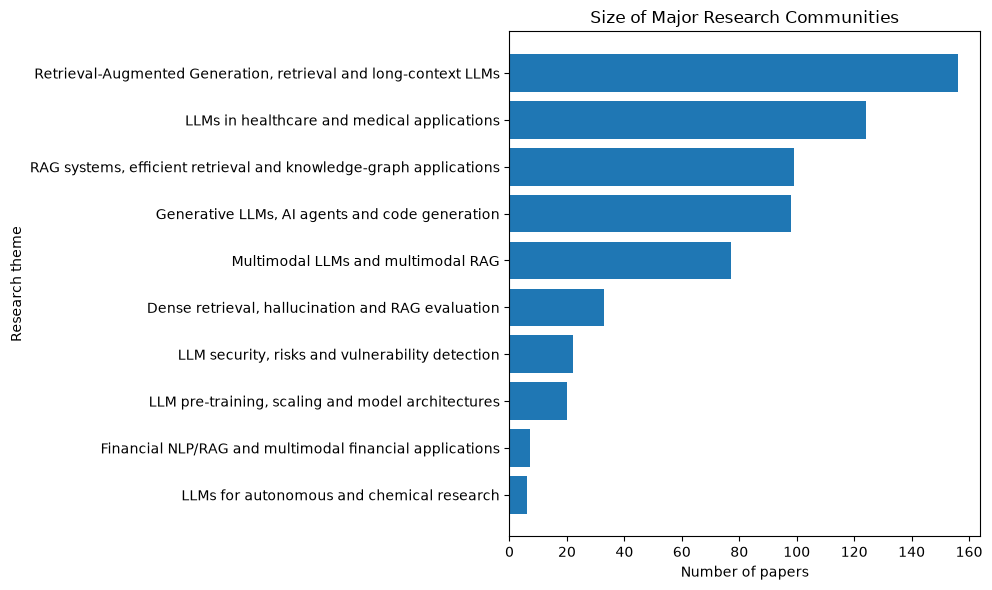

In [20]:
import matplotlib.pyplot as plt

# Plot size of the 10 largest research communities

plot_df = community_results.sort_values(
    "paper_count",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["theme"],
    plot_df["paper_count"]
)

plt.xlabel("Number of papers")
plt.ylabel("Research theme")
plt.title("Size of Major Research Communities")

plt.tight_layout()
plt.show()

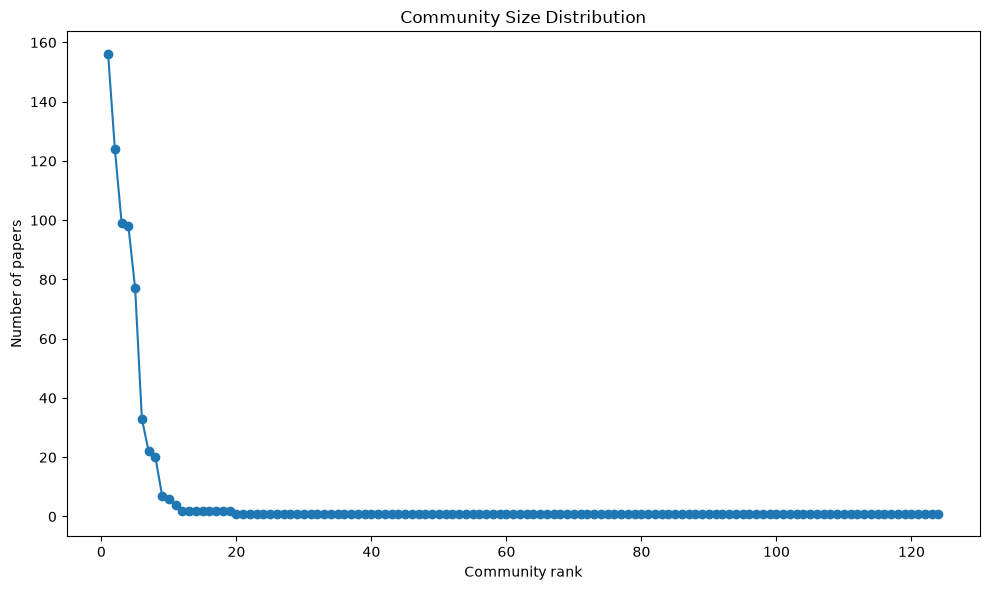

In [21]:
# Community size distribution

plt.figure(figsize=(10, 6))

community_sizes_plot = (
    community_df["community"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.plot(
    range(1, len(community_sizes_plot) + 1),
    community_sizes_plot.values,
    marker="o"
)

plt.xlabel("Community rank")
plt.ylabel("Number of papers")
plt.title("Community Size Distribution")

plt.tight_layout()
plt.show()

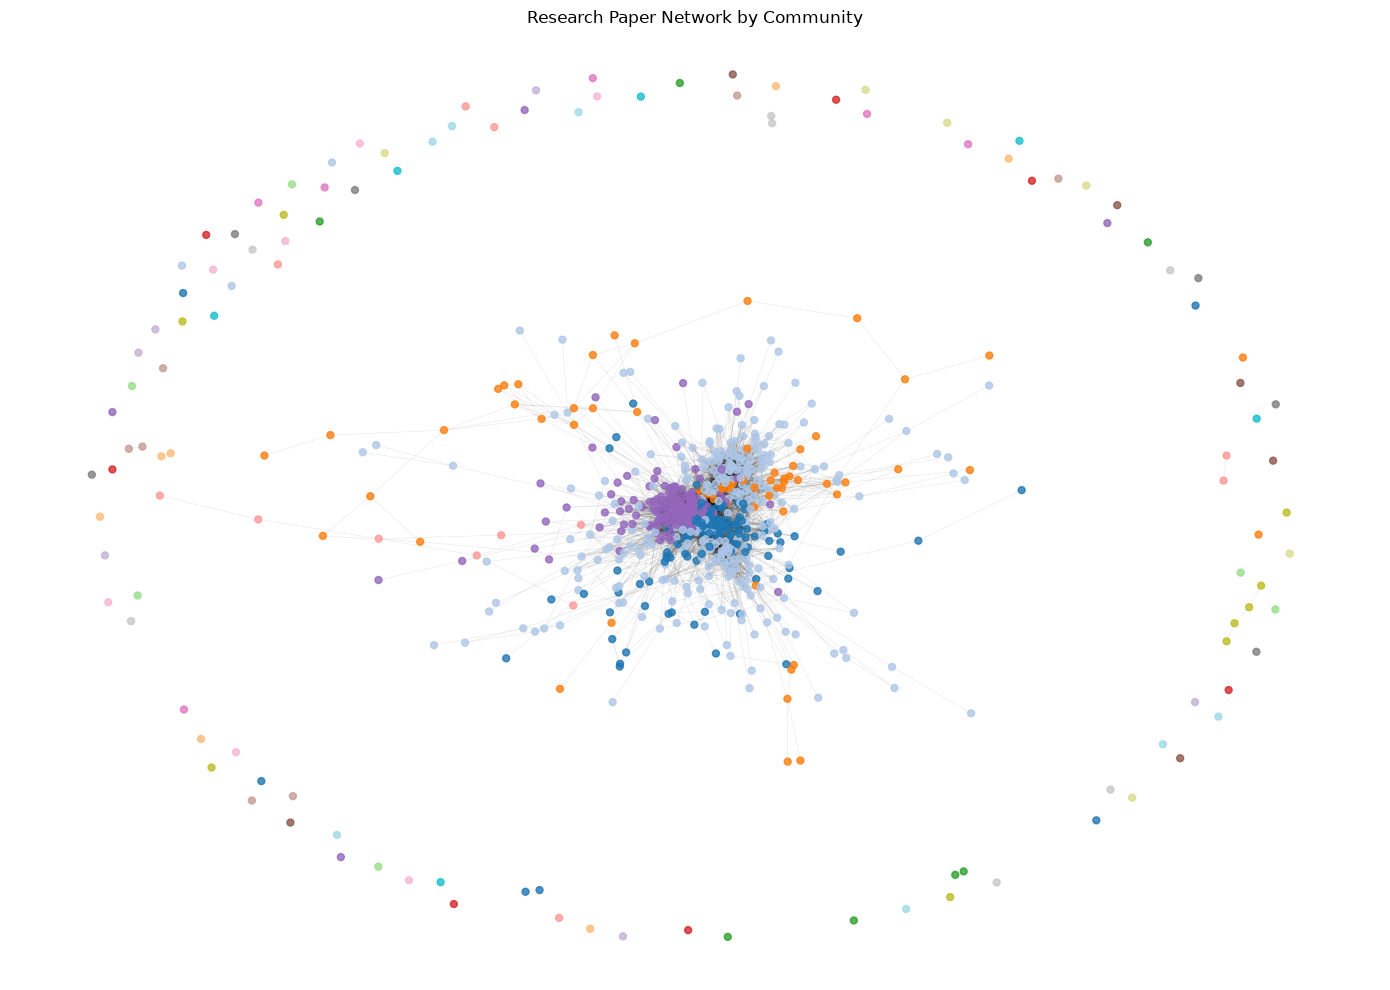

In [22]:
# Visualize the research network with community structure

import matplotlib.pyplot as plt
import networkx as nx

plt.figure(figsize=(14, 10))

# Use a layout suitable for the full graph
pos = nx.spring_layout(
    G,
    seed=42,
    k=0.15,
    iterations=50
)

# Draw edges lightly
nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.08,
    width=0.5
)

# Draw nodes colored by community
communities = [G.nodes[node]["community"] for node in G.nodes()]

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=25,
    node_color=communities,
    cmap="tab20",
    alpha=0.8
)

plt.title("Research Paper Network by Community")
plt.axis("off")
plt.tight_layout()
plt.show()

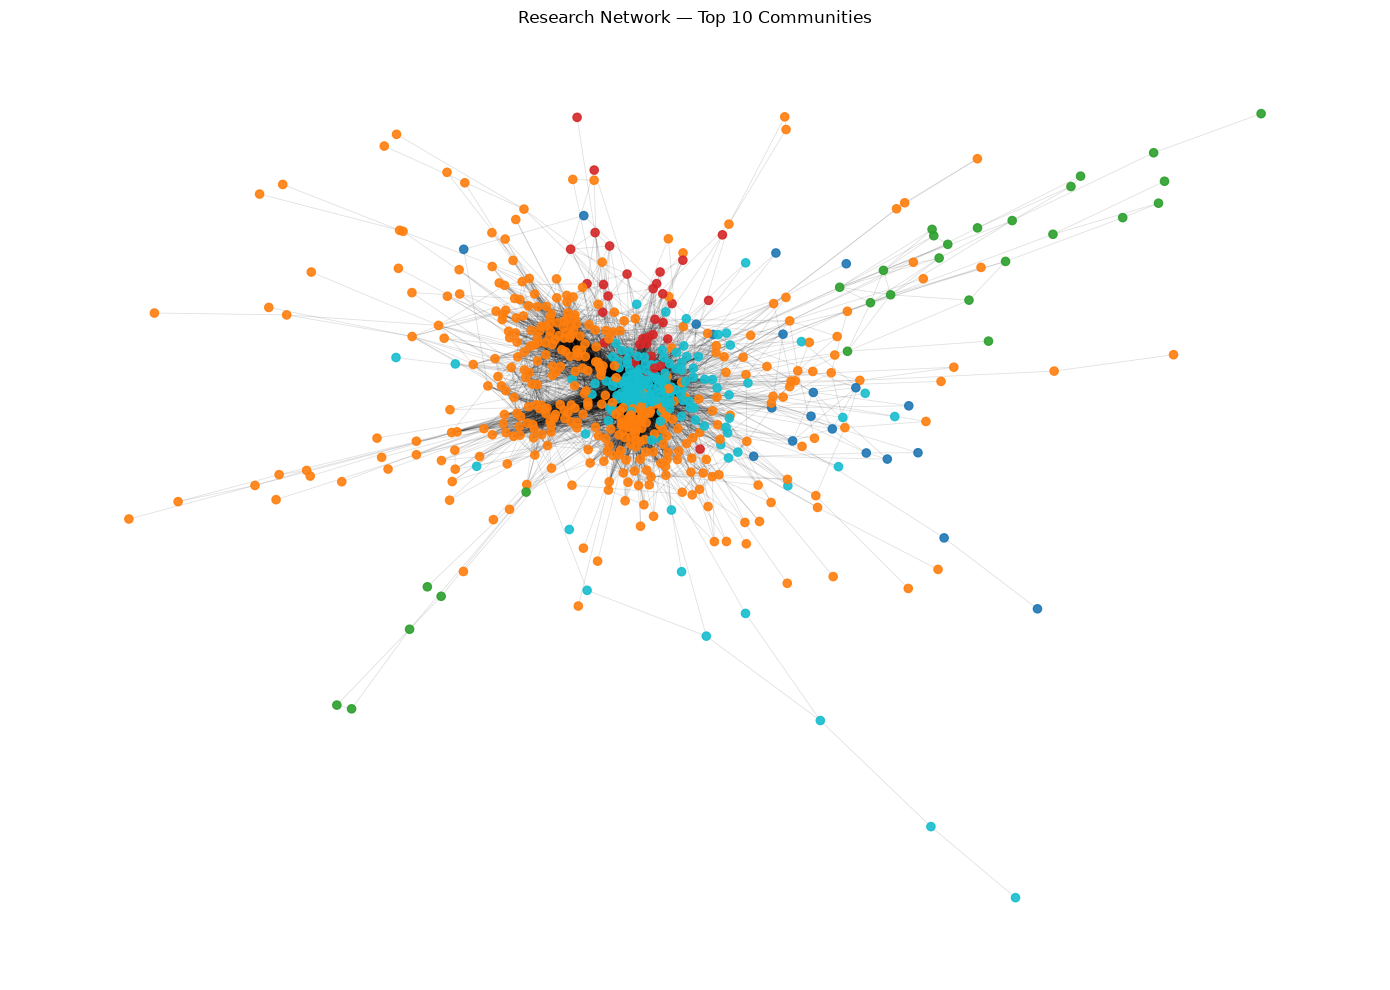

In [23]:
# Visualize the 10 largest research communities

top_10_communities = (
    community_df["community"]
    .value_counts()
    .head(10)
    .index
)

# Keep only nodes belonging to the 10 largest communities
top_nodes = [
    node for node, data in G.nodes(data=True)
    if data.get("community") in top_10_communities
]

subgraph = G.subgraph(top_nodes).copy()

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    subgraph,
    seed=42,
    k=0.25,
    iterations=100
)

nx.draw_networkx_edges(
    subgraph,
    pos,
    alpha=0.12,
    width=0.6
)

node_communities = [
    subgraph.nodes[node]["community"]
    for node in subgraph.nodes()
]

nx.draw_networkx_nodes(
    subgraph,
    pos,
    node_size=35,
    node_color=node_communities,
    cmap="tab10",
    alpha=0.9
)

plt.title("Research Network — Top 10 Communities")
plt.axis("off")
plt.tight_layout()
plt.show()

In [24]:
# Centrality analysis

print("Calculating centrality measures...")

# Degree centrality
degree_centrality = nx.degree_centrality(G)

# Betweenness centrality
betweenness_centrality = nx.betweenness_centrality(
    G,
    weight="weight",
    normalized=True
)

# PageRank
pagerank = nx.pagerank(
    G,
    weight="weight"
)

# Store results as node attributes
nx.set_node_attributes(
    G,
    degree_centrality,
    "degree_centrality"
)

nx.set_node_attributes(
    G,
    betweenness_centrality,
    "betweenness_centrality"
)

nx.set_node_attributes(
    G,
    pagerank,
    "pagerank"
)

print("Centrality calculations completed.")

Calculating centrality measures...
Centrality calculations completed.


In [25]:
# Create centrality DataFrame

centrality_df = pd.DataFrame({
    "node": list(G.nodes()),
    "degree_centrality": [
        G.nodes[n]["degree_centrality"]
        for n in G.nodes()
    ],
    "betweenness_centrality": [
        G.nodes[n]["betweenness_centrality"]
        for n in G.nodes()
    ],
    "pagerank": [
        G.nodes[n]["pagerank"]
        for n in G.nodes()
    ]
})

# Add paper metadata
centrality_df["title"] = centrality_df["node"].map(
    nx.get_node_attributes(G, "title")
)

centrality_df["year"] = centrality_df["node"].map(
    nx.get_node_attributes(G, "year")
)

centrality_df["citation_count"] = centrality_df["node"].map(
    nx.get_node_attributes(G, "citation_count")
)

centrality_df["community"] = centrality_df["node"].map(
    nx.get_node_attributes(G, "community")
)

centrality_df.head()

,node,degree_centrality,betweenness_centrality,pagerank,title,year,citation_count,community
0,0,0.022193,0.004710,0.001628,A Comprehensive Overview of Large Language Models,2023,368,0
1,1,0.020888,0.002881,0.001039,A Comprehensive Survey of Hallucination Mitiga...,2024,122,17
2,2,0.251958,0.016045,0.006846,A Comprehensive Survey of Retrieval-Augmented ...,2024,23,51
3,3,0.000000,0.000000,0.000221,A Comprehensive Survey of Retrieval-Augmented ...,2025,28,3
4,4,0.100522,0.002543,0.002888,A Comprehensive Survey on Multimodal RAG: All ...,2025,2,7


In [26]:
# Top papers by each centrality measure

top_degree = centrality_df.sort_values(
    "degree_centrality",
    ascending=False
).head(10)

top_betweenness = centrality_df.sort_values(
    "betweenness_centrality",
    ascending=False
).head(10)

top_pagerank = centrality_df.sort_values(
    "pagerank",
    ascending=False
).head(10)

print("=" * 80)
print("TOP 10 — DEGREE CENTRALITY")
print("=" * 80)

print(
    top_degree[
        ["title", "year", "citation_count", "community", "degree_centrality"]
    ].to_string(index=False)
)

print("\n" + "=" * 80)
print("TOP 10 — BETWEENNESS CENTRALITY")
print("=" * 80)

print(
    top_betweenness[
        ["title", "year", "citation_count", "community", "betweenness_centrality"]
    ].to_string(index=False)
)

print("\n" + "=" * 80)
print("TOP 10 — PAGERANK")
print("=" * 80)

print(
    top_pagerank[
        ["title", "year", "citation_count", "community", "pagerank"]
    ].to_string(index=False)
)

TOP 10 — DEGREE CENTRALITY
                                                                                                             title  year  citation_count  community  degree_centrality
A Comprehensive Survey of Retrieval-Augmented Generation (RAG): Evolution, Current Landscape and Future Directions  2024              23         51           0.251958
                        Retrieval-Augmented Generation to Generate Knowledge Assets and Creation of Action Drivers  2025              22          6           0.229765
                                   A Survey on RAG Meeting LLMs: Towards Retrieval-Augmented Large Language Models  2024             757         51           0.228460
                                                          Benchmarking Retrieval-Augmented Generation for Medicine  2024             269          8           0.224543
                     Leveraging long context in retrieval augmented language models for medical question answering  2025              77  

In [27]:
# Compact comparison of the three centrality measures

centrality_comparison = centrality_df[
    [
        "title",
        "year",
        "citation_count",
        "community",
        "degree_centrality",
        "betweenness_centrality",
        "pagerank"
    ]
].copy()

print("TOP 10 BY PAGERANK")
print("=" * 100)

print(
    centrality_comparison
    .sort_values("pagerank", ascending=False)
    .head(10)
    .to_string(index=False)
)

TOP 10 BY PAGERANK
                                                                                                             title  year  citation_count  community  degree_centrality  betweenness_centrality  pagerank
A Comprehensive Survey of Retrieval-Augmented Generation (RAG): Evolution, Current Landscape and Future Directions  2024              23         51           0.251958                0.016045  0.006846
                        Retrieval-Augmented Generation to Generate Knowledge Assets and Creation of Action Drivers  2025              22          6           0.229765                0.022031  0.006423
                                                          Benchmarking Retrieval-Augmented Generation for Medicine  2024             269          8           0.224543                0.017734  0.006021
                                   A Survey on RAG Meeting LLMs: Towards Retrieval-Augmented Large Language Models  2024             757         51           0.228460           

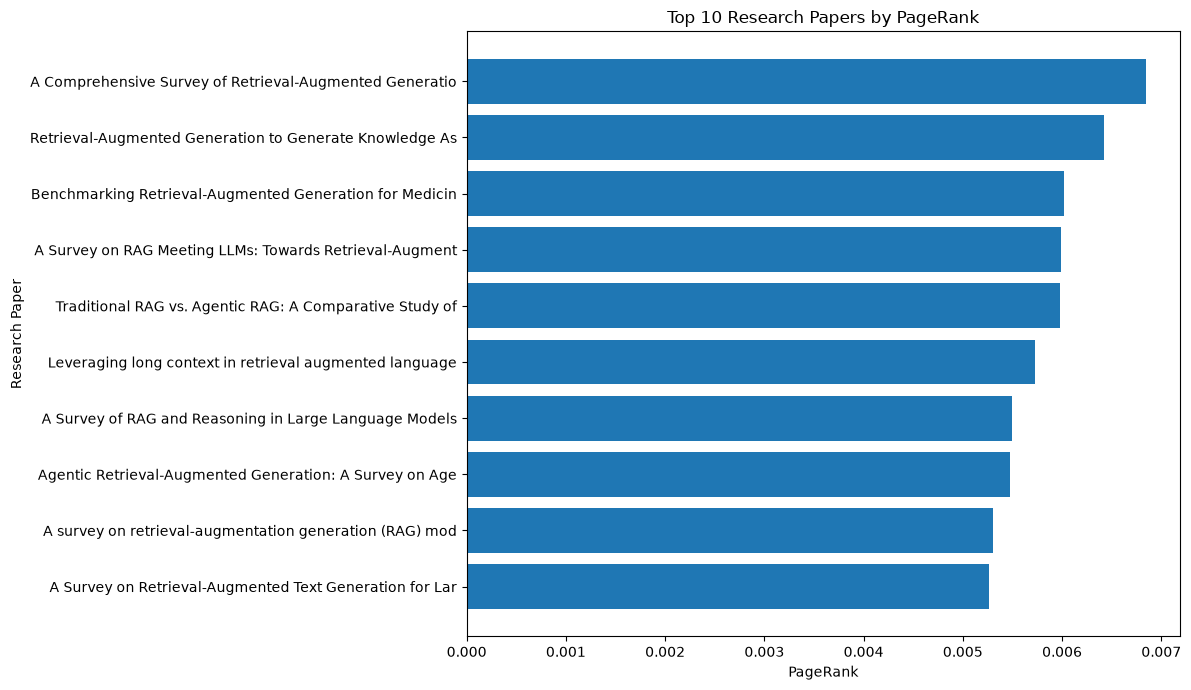

In [28]:
# Visualize the top 10 papers by PageRank

top_pagerank = (
    centrality_df
    .sort_values("pagerank", ascending=False)
    .head(10)
    .copy()
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_pagerank["title"].str.slice(0, 55)[::-1],
    top_pagerank["pagerank"][::-1]
)

plt.xlabel("PageRank")
plt.ylabel("Research Paper")
plt.title("Top 10 Research Papers by PageRank")

plt.tight_layout()
plt.show()

In [29]:
# Save centrality results for later use

centrality_df.to_parquet(
    "../data/processed/paper_centrality.parquet",
    index=False
)

print("Centrality results saved successfully.")

Centrality results saved successfully.
